# Lecture 1 — Missing data and exact Gaussian queries

Four coordinates of one measurement vector are recorded; three are withheld. A supplied joint Gaussian lets us reconstruct the hidden block **as a distribution**, choose a point action under squared loss, and ask a different question about measurements of a fresh case.

The model parameters are known throughout. The numerical example is course-constructed, not a fitted model or a Murphy dataset. We apply the lecture's equations rather than rederive them.

Work through each small question in order. Write prose/mathematics or code as requested. Cells marked **[GIVEN]** are supplied: read them and run their code. In the solved version, each question is followed immediately by its answer; those answers become placeholders in the self-work version.

## 0. Given model, case and plotting infrastructure

**[GIVEN]** Write $X=(X_1^T,X_2^T)^T$ with $X_1\in\mathbb R^3$ and $X_2\in\mathbb R^4$. We know
$$
X\sim\mathcal N\!\left(\begin{pmatrix}\mu_1\\\mu_2\end{pmatrix},
\begin{pmatrix}\Sigma_{11}&\Sigma_{12}\\\Sigma_{21}&\Sigma_{22}\end{pmatrix}\right),
\qquad \mu_1=(-0.5,0.5,1)^T,\quad\mu_2=(0,0.5,-0.5,1)^T.
$$

The supplied joint covariance is positive definite, so its diagonal blocks and conditional Schur complements are invertible. Supplied author checks verify this numerical example. The synthetic covariance construction below is supplied infrastructure. It uses $J_d=\mathbf1_d\mathbf1_d^T$, $\sigma_1=1$, $\sigma_2=1.2$, $\rho_1=0.70$, $\rho_2=0.80$, $\kappa=0.90$:
$$
\Sigma_{11}=\sigma_1^2[(1-\rho_1)I_3+\rho_1J_3],\qquad
\Sigma_{22}=\sigma_2^2[(1-\rho_2)I_4+\rho_2J_4],
$$
$$
\Sigma_{12}=\kappa\sigma_1\sigma_2\sqrt{\rho_1\rho_2}\,\mathbf1_3\mathbf1_4^T,
\qquad\Sigma_{21}=\Sigma_{12}^T.
$$

`np.block([[A, B], [C, D]])` joins compatible matrix blocks in the displayed two-by-two layout. Here it assembles the full covariance. `np.eye(d)` and `np.ones((d,d))` construct $I_d$ and $J_d$; these arbitrary setup choices are not exercises.

The supplied complete case below was originally generated with seed 2027 under NumPy 2.0.2. We retain its full-precision coordinates as fixed example data: a seeded multivariate-normal draw can change across numerical libraries when a covariance has repeated eigenvalues. This is provenance, not a promise that regenerating that seed gives the same case everywhere. Only `x2_obs` is printed and used for inference. The retained hidden value is revealed later for evaluation. Fresh generation uses a separate supplied seed 2028 and has no fixed numerical answer key.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

np.set_printoptions(precision=6, suppress=True)
n1, n2 = 3, 4
mu1 = np.array([-0.5, 0.5, 1.0])
mu2 = np.array([0.0, 0.5, -0.5, 1.0])
mu = np.concatenate([mu1, mu2])
sigma1, sigma2 = 1.0, 1.2
rho1, rho2, kappa = 0.70, 0.80, 0.90
Sigma11 = sigma1**2 * ((1-rho1)*np.eye(n1) + rho1*np.ones((n1,n1)))
Sigma22 = sigma2**2 * ((1-rho2)*np.eye(n2) + rho2*np.ones((n2,n2)))
Sigma12 = kappa*sigma1*sigma2*np.sqrt(rho1*rho2)*np.ones((n1,n2))
Sigma21 = Sigma12.T
Sigma = np.block([[Sigma11, Sigma12], [Sigma21, Sigma22]])

# Fixed reference case: original seed 2027 / NumPy 2.0.2 provenance.
x_complete = np.array([
    -0.9809265055186939, -0.275006600480288, 1.8920470230380393,
    -0.18413093623310994, -0.06973754657319287,
    -0.07777903828206933, 0.9191872262734604,
])
x1_true = x_complete[:n1].copy()  # Retained only for later evaluation.
x2_obs = x_complete[n1:].copy()  # This is the inference input.
print("Observed block x2_obs:", x2_obs)

# Supplied plot helpers: no model inference is hidden here.
# norm.ppf(0.95) is the standard-normal 95th percentile, about 1.64485.
z90 = norm.ppf(0.95)
def plot_joint_correlation():
    sd = np.sqrt(np.diag(Sigma))
    corr = Sigma / np.outer(sd, sd)
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    fig.colorbar(im, ax=ax, label="correlation")
    labels = [f"x1[{j}]" for j in range(n1)] + [f"x2[{j}]" for j in range(n2)]
    ax.set_xticks(range(n1+n2), labels, rotation=45, ha="right")
    ax.set_yticks(range(n1+n2), labels)
    ax.axvline(n1-0.5, color="black", linewidth=1)
    ax.axhline(n1-0.5, color="black", linewidth=1)
    ax.set_title("Known joint Gaussian: correlation structure")
    fig.tight_layout()
    plt.show()
    return fig

def plot_hidden_uncertainty(mean, sd, truth):
    positions = np.arange(n1)
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.errorbar(positions-0.08, mu1, yerr=z90*np.sqrt(np.diag(Sigma11)),
                fmt="s", capsize=4, color="gray", label="Unconditional mean + individual 90% interval")
    ax.errorbar(positions+0.08, mean, yerr=z90*sd,
                fmt="o", capsize=4, color="tab:blue", label="Conditional mean + individual 90% interval")
    ax.scatter(positions, truth, marker="D", color="tab:orange", s=40,
               label="Hidden simulation truth (reference only)", zorder=3)
    ax.set_xticks(positions, [f"x1[{j}]" for j in range(n1)])
    ax.set_ylabel("value")
    ax.set_title("Hidden block: exact marginal uncertainty")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5,-0.10))
    fig.tight_layout()
    plt.show()
    return fig

def plot_forward_measurements(mean, cov, generated, recorded):
    positions = np.arange(n2)
    fig, ax = plt.subplots(figsize=(8, 5.7))
    ax.errorbar(positions, mean, yerr=z90*np.sqrt(np.diag(cov)),
                fmt="o", capsize=5, color="black", label="Forward mean + individual 90% interval")
    ax.scatter(positions+0.06, generated, marker="x", s=45,
               color="tab:blue", label="One fresh generated case", zorder=3)
    ax.scatter(positions, recorded, marker="D", s=35,
               color="tab:orange", label="Original recorded case (reference only)", zorder=3)
    ax.set_xticks(positions, [f"y[{j}]" for j in range(n2)])
    ax.set_ylabel("value")
    ax.set_title("Before observing a fresh case: the forward measurement law")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5,-0.10))
    fig.tight_layout()
    plt.show()
    return fig

Observed block x2_obs: [-0.184131 -0.069738 -0.077779  0.919187]


## 1. Read the known joint and identify the task

**[GIVEN]** `x_complete[:n1]` selected the first three components; `x_complete[n1:]` selected the remaining four. NumPy vectors use shapes `(3,)` and `(4,)`, rather than two-dimensional column arrays. This convention still permits ordinary matrix-vector multiplication with `@`.

### 1.1 Identify the covariance blocks — mathematics

For $X_1\in\mathbb R^3$ and $X_2\in\mathbb R^4$, state the shape of each of $\Sigma_{11},\Sigma_{12},\Sigma_{21},\Sigma_{22}$ and the full $\Sigma$. Explain which pairs of coordinates an entry of $\Sigma_{12}$ describes.

The shapes are $3\times3$, $3\times4$, $4\times3$, $4\times4$, and $7\times7$, respectively. Entry $(i,j)$ of $\Sigma_{12}$ is $\operatorname{Cov}(X_{1i},X_{2j})$: a covariance between a hidden-block and an observed-block coordinate.

### 1.2 Calculate a covariance and its correlation — mathematics

The supplied construction makes every cross-block covariance equal to $\kappa\sigma_1\sigma_2\sqrt{\rho_1\rho_2}$. Using the given parameter values, calculate $\operatorname{Cov}(X_{11},X_{21})$ and divide by the marginal standard deviations $\sigma_1\sigma_2$ to obtain $\operatorname{Corr}(X_{11},X_{21})$. Also state the correlations between distinct coordinates within each block.

$$
\operatorname{Cov}(X_{11},X_{21})=0.90(1)(1.2)\sqrt{0.70\cdot0.80}\approx0.808198,
$$
$$
\operatorname{Corr}(X_{11},X_{21})=0.90\sqrt{0.70\cdot0.80}\approx0.673498.
$$
Distinct coordinates have correlation $0.70$ within $X_1$ and $0.80$ within $X_2$. The nonzero cross-block dependence makes the recorded block informative about the hidden block in this Gaussian model.

**[GIVEN]** Run this supplied display and locate the two within-block regions and the cross-block region. The plot expresses the same known covariances after standardization.

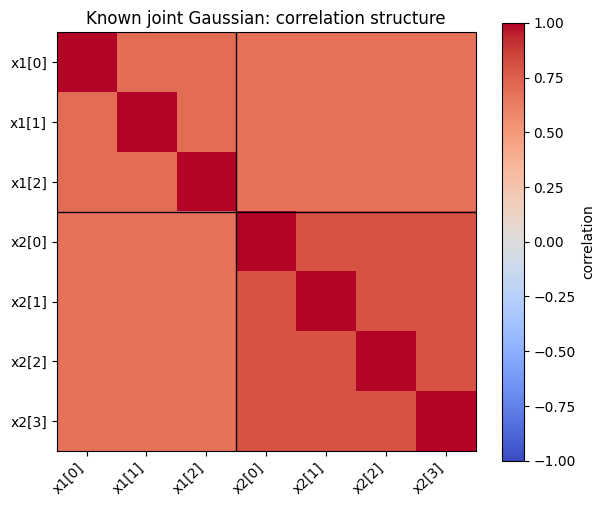

In [2]:
_ = plot_joint_correlation()

**[GIVEN] Task framing.** The lecture's discovery schema is $p_D(z_*\mid x_*)$, with $z_*$ an unobserved part of a case and $x_*$ its available information. Here the joint model is supplied rather than estimated from a training dataset. Its parameters $\mu,\Sigma$ are fixed. Reconstruction should first report a conditional distribution; choosing a single action requires a loss function.

### 1.3 Specify this reconstruction problem — prose and mathematics

We withhold the three values in `x1_true`, observe the four values in `x2_obs`, and know $\mu,\Sigma$. Identify $z_*$ and $x_*$ in the discovery schema $p_D(z_*\mid x_*)$, write the concrete target distribution, and distinguish the unknown values from model parameters.

Here $z_*=X_1$ and $x_*=x_{2,\mathrm{obs}}$. The target is
$$
p(x_1\mid x_{2,\mathrm{obs}},\mu,\Sigma).
$$
This is discovery of the hidden coordinates of this case. The unknown is a three-dimensional value, not $\mu$ or $\Sigma$. Those parameters are supplied, so this notebook performs inference with a known model and no parameter fitting. `x1_true` is a separately retained evaluation reference, not evidence supplied to this conditional.

**[GIVEN] Section summary.** We identified the hidden/recorded covariance blocks, their cross-block dependence, and the conditional distribution required for this known-model reconstruction task.

## 2. Evaluate the exact conditional distribution

**[GIVEN]** Apply the lecture's block-Gaussian equations:
$$
X_1\mid X_2=x_{2,\mathrm{obs}}\sim\mathcal N(m,V),
$$
$$
m=\mu_1+\Sigma_{12}\Sigma_{22}^{-1}(x_{2,\mathrm{obs}}-\mu_2),\qquad
V=\Sigma_{11}-\Sigma_{12}\Sigma_{22}^{-1}\Sigma_{21}.
$$

The innovation $x_{2,\mathrm{obs}}-\mu_2$ is the observed deviation from the model's mean. `np.linalg.solve(A, B)` solves $AU=B$ for $U$; when $A$ is invertible, this evaluates $A^{-1}B$ without explicitly forming an inverse. A vector right-hand side produces a vector; a matrix right-hand side solves for all its columns. Keep the displayed multiplication order.

### 2.1 Compute the conditional mean — code

Using `np.linalg.solve(A, B)` for $A^{-1}B$, calculate `innovation = x2_obs - mu2` and
$$
m=\mu_1+\Sigma_{12}\Sigma_{22}^{-1}(x_{2,\mathrm{obs}}-\mu_2).
$$
Store the result as `conditional_mean`; print it and its shape. Check in a code comment how a $(3,4)$ matrix acts on the solved $(4,)$ vector.

In [3]:
innovation = x2_obs - mu2
# Sigma12 (3,4) @ solved innovation (4,) produces a (3,) vector.
conditional_mean = mu1 + Sigma12 @ np.linalg.solve(Sigma22, innovation)
print("Conditional mean:", conditional_mean)
print("Shape:", conditional_mean.shape)

Conditional mean: [-0.568086  0.431914  0.931914]
Shape: (3,)


### 2.2 Compute the conditional covariance — code

Use a matrix right-hand side in `np.linalg.solve(Sigma22, Sigma21)` to evaluate
$$
V=\Sigma_{11}-\Sigma_{12}\Sigma_{22}^{-1}\Sigma_{21}.
$$
Store it as `conditional_cov`, print it and its shape, and give the shapes of the solve result and final product in a code comment.

In [4]:
# solve result: (4,3); Sigma12 (3,4) @ result (4,3) gives (3,3).
conditional_cov = Sigma11 - Sigma12 @ np.linalg.solve(Sigma22, Sigma21)
print("Conditional covariance:\n", conditional_cov)
print("Shape:", conditional_cov.shape)

Conditional covariance:
 [[0.466353 0.166353 0.166353]
 [0.166353 0.466353 0.166353]
 [0.166353 0.166353 0.466353]]
Shape: (3, 3)


**[GIVEN] Marginal summaries.** For covariance $V$, `np.diag(V)` extracts its diagonal variances; `np.sqrt(...)` gives the marginal standard deviations. A Gaussian coordinate with mean $m_j$ and SD $s_j$ has central 90% interval
$$
[m_j-q s_j,\ m_j+q s_j],\qquad q=\Phi^{-1}(0.95)\approx1.64485.
$$
The supplied `z90 = norm.ppf(0.95)` is this normal quantile. These are **individual marginal intervals**: each coordinate has conditional probability 0.90 in its own interval. The full covariance still contains cross-coordinate dependence.

### 2.3 Summarize the marginal uncertainties — code

For the exact law $\mathcal N(\texttt{conditional_mean},\texttt{conditional_cov})$, compute `conditional_sd` from the diagonal, then the lower and upper central 90% endpoints using the supplied `z90`. Store the endpoints as `conditional_90_low` and `conditional_90_high` and print all three arrays.

In [5]:
conditional_sd = np.sqrt(np.diag(conditional_cov))
conditional_90_low = conditional_mean - z90 * conditional_sd
conditional_90_high = conditional_mean + z90 * conditional_sd
print("Marginal SD:", conditional_sd)
print("Individual 90% lower:", conditional_90_low)
print("Individual 90% upper:", conditional_90_high)

Marginal SD: [0.6829 0.6829 0.6829]
Individual 90% lower: [-1.691357 -0.691357 -0.191357]
Individual 90% upper: [0.555185 1.555185 2.055185]


### 2.4 What has been computed? — prose

Our exact result is $\mathcal N(m,V)$, with three individual marginal 90% intervals. Explain why reporting only $m$ loses information, and why the probability that **all three** coordinates fall in their displayed intervals cannot simply be labelled 90%. Which computed object retains the conditional dependence?

The mean $m$ is a point summary; it omits the uncertainty about the unknown vector. Each interval describes one marginal coordinate, so its 90% statement does not imply a simultaneous 90% statement for the vector. The covariance $V$ retains the variances and cross-coordinate covariances. It is part of the exact conditional law, not an uncertainty in an estimated mean.

**[GIVEN]** Inference is now complete. Run this supplied evaluation display to reveal the withheld values. The reference values enter only this display and the later realized-error calculation; they did not enter `conditional_mean` or `conditional_cov`. The gray intervals describe the original unconditional hidden-block marginal; the blue intervals describe conditioning on this case's observed block.

Hidden simulation truth (evaluation only): [-0.980927 -0.275007  1.892047]


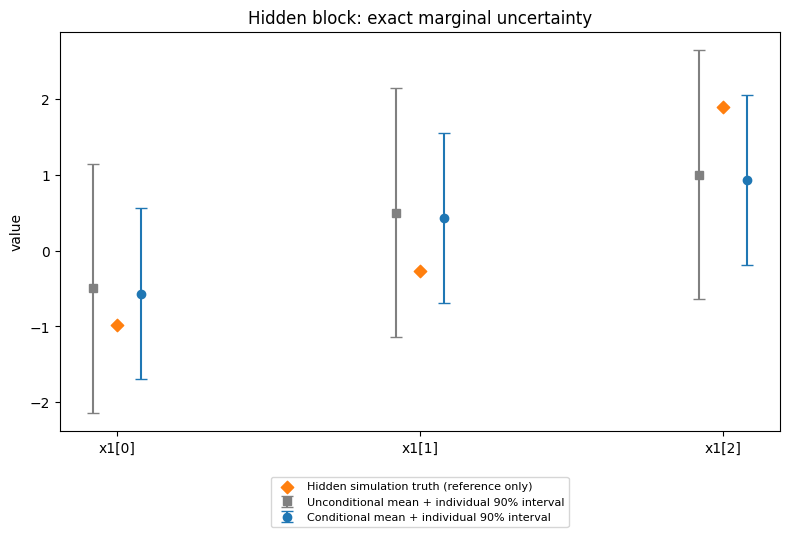

In [6]:
print("Hidden simulation truth (evaluation only):", x1_true)
_ = plot_hidden_uncertainty(conditional_mean, conditional_sd, x1_true)

**[GIVEN] Section summary.** The conditional mean is approximately $(-0.568,0.432,0.932)$ and each marginal SD is approximately $0.683$. We evaluated the full exact Gaussian law and its individual marginal intervals. Remaining uncertainty is present even with exact computation; the hidden reference need not equal the conditional mean.

## 3. Select an action under squared loss

**[GIVEN]** The lecture's vector squared-loss identity gives, for any chosen action $a\in\mathbb R^3$,
$$
R(a\mid x_{2,\mathrm{obs}})
=E_{\mathrm{model}}[\|X_1-a\|^2\mid x_{2,\mathrm{obs}}]
=\operatorname{tr}(V)+\|m-a\|^2.
$$
Here $m$ and $V$ are the conditional mean/covariance already computed. The loss is the **sum** of squared coordinate errors, without dividing by three. This identity requires finite conditional second moments; Gaussianity supplies the particular exact law above.

`np.trace(V)` adds a matrix's diagonal entries. `np.sum((u-v)**2)` computes the squared Euclidean distance between same-shaped vectors.

### 3.1 Choose the squared-loss action — mathematics

Using $R(a\mid x_{2,\mathrm{obs}})=\operatorname{tr}(V)+\|m-a\|^2$, identify the minimizing action and the minimum conditional model risk. Which term describes irreducible conditional uncertainty, and which term penalizes choosing another action? Apply the supplied identity; no new proof is required.

The squared distance is nonnegative and vanishes exactly when $a=m$, so
$$
a^*=m,\qquad R(a^*\mid x_{2,\mathrm{obs}})=\operatorname{tr}(V).
$$
The trace describes remaining conditional uncertainty under the supplied model. The term $\|m-a\|^2$ is the excess conditional risk caused by choosing another action. This selects a point decision from a distribution; it does not replace that distribution.

### 3.2 Compute the chosen action and its model risk — code

Set `action_mean` to the exact `conditional_mean`, then use `np.trace(conditional_cov)` to calculate `risk_mean`, the minimum conditional expected **sum** of squared errors. Print the action and risk. Do not use `x1_true` in this calculation.

In [7]:
action_mean = conditional_mean
risk_mean = np.trace(conditional_cov)
print("Squared-loss action:", action_mean)
print("Minimum conditional model risk:", risk_mean)

Squared-loss action: [-0.568086  0.431914  0.931914]
Minimum conditional model risk: 1.399058823529412


**[GIVEN] One realized error.** The following supplied evaluation uses the withheld vector once. It computes this draw's actual $\|x_{1,\mathrm{true}}-a^*\|^2$, rather than an expectation over the conditional model.

In [8]:
realized_error_mean = np.sum((x1_true - action_mean)**2)
print("Conditional model expected risk:", risk_mean)
print("This case's realized squared error:", realized_error_mean)

Conditional model expected risk: 1.399058823529412
This case's realized squared error: 1.5920294059108695


### 3.3 Separate expected risk from this draw's error — prose

The supplied cell prints `risk_mean` and `realized_error_mean`. Explain what is averaged in the former, why the two numbers need not be equal, and whether a small error on this one hidden case validates the Gaussian model or establishes average real-world reconstruction performance.

`risk_mean` averages squared error over $X_1\mid X_2=x_{2,\mathrm{obs}}$ under the supplied model. `realized_error_mean` uses one particular hidden value from that distribution; individual losses vary, so equality is not expected. Squared-loss optimality is an expected-risk statement, not guaranteed exact reconstruction of every case. One simulated case does not validate the model or establish average real-world performance.

**[GIVEN] Section summary.** Squared loss selects the conditional mean and minimum conditional model risk `trace(conditional_cov)`, approximately 1.399059. This risk is distinct from one realization's error and from an empirical claim about a real population.

## 4. Express the same joint as a linear Gaussian system

**[GIVEN]** The lecture's LGS notation writes
$$
Z\sim\mathcal N(\mu_z,\Sigma_z),\qquad Y=WZ+b+\varepsilon,
\qquad \varepsilon\sim\mathcal N(0,\Omega),\quad \varepsilon\perp Z.
$$
The state is the hidden block and the measurement is the recorded block. We are factoring the existing joint as $p(z)p(y\mid z)$, with no new fitting. This synthetic representation does not infer a physical sensor or causal mechanism from the covariance.

### 4.1 Make the notation mapping explicit — code with comments

The hidden block was $X_1$ and the recorded block was $X_2$. Assign `mu_z`, `Sigma_z` and `y` from the existing arrays. Use comments to state the mapping of $Z,Y$ and the shapes of their means/covariances.

In [9]:
# Z = X1 in R^3; mu_z has shape (3,) and Sigma_z has shape (3,3).
mu_z = mu1
Sigma_z = Sigma11
# Y = X2 in R^4; y is this case's observed measurement, shape (4,).
y = x2_obs

**[GIVEN]** In the original block notation, the conditional observation law is
$$
E[X_2\mid X_1]=\mu_2+\Sigma_{21}\Sigma_{11}^{-1}(X_1-\mu_1),
$$
$$
\operatorname{Cov}(X_2\mid X_1)
=\Sigma_{22}-\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12}.
$$
These are the same conditional-Gaussian equations with the block roles exchanged. Use them to identify the LGS parameters, then stay in LGS notation for the forward query.

### 4.2 Identify the LGS parameters — mathematics

With $Z=X_1$ and $Y=X_2$, match the supplied conditional mean to $WZ+b$ and the conditional covariance to $\Omega$. Write $W,b,\Omega$ in terms of the original blocks, and give their shapes.

$$
W=\Sigma_{21}\Sigma_{11}^{-1}\quad(4\times3),\qquad
b=\mu_2-W\mu_1\quad(4\text{-vector}),
$$
$$
\Omega=\Sigma_{22}-\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12}\quad(4\times4).
$$
$\Omega$ is the residual measurement covariance conditional on the state; it is not the unconditional covariance of $Y$.

**[GIVEN] Right-side inverse.** `solve(A, B)` directly computes a left-side inverse product $A^{-1}B$. To evaluate $W=\Sigma_{21}\Sigma_{11}^{-1}$, use symmetry $\Sigma_{11}^T=\Sigma_{11}$ and $\Sigma_{12}^T=\Sigma_{21}$:
$$
(\Sigma_{11}^{-1}\Sigma_{12})^T=\Sigma_{21}\Sigma_{11}^{-1}.
$$
Thus `np.linalg.solve(Sigma11, Sigma12).T` produces the $(4,3)$ matrix. `.T` transposes a matrix; transposing a one-dimensional NumPy vector does not create a column array.

### 4.3 Implement the observation mean — code

Use the supplied transpose/solve identity to compute `W = Sigma21 @ inverse(Sigma11)` without forming the inverse, then compute `b = mu2 - W @ mu1`. Print `W`, `b` and their shapes.

In [10]:
W = np.linalg.solve(Sigma11, Sigma12).T
b = mu2 - W @ mu1
print("W:\n", W)
print("b:", b)
print("Shapes:", W.shape, b.shape)

W:
 [[0.336749 0.336749 0.336749]
 [0.336749 0.336749 0.336749]
 [0.336749 0.336749 0.336749]
 [0.336749 0.336749 0.336749]]
b: [-0.336749  0.163251 -0.836749  0.663251]
Shapes: (4, 3) (4,)


### 4.4 Implement the residual covariance — code

Apply
$$
\Omega=\Sigma_{22}-\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12}
$$
using `np.linalg.solve(Sigma11, Sigma12)` for the inverse product. Store the result as `Omega`, print it and its shape, and identify in a code comment why its shape is $(4,4)$.

In [11]:
# Measurement noise has four components, so its covariance is (4,4).
Omega = Sigma22 - Sigma21 @ np.linalg.solve(Sigma11, Sigma12)
print("Omega:\n", Omega)
print("Shape:", Omega.shape)

Omega:
 [[0.62352 0.33552 0.33552 0.33552]
 [0.33552 0.62352 0.33552 0.33552]
 [0.33552 0.33552 0.62352 0.33552]
 [0.33552 0.33552 0.33552 0.62352]]
Shape: (4, 4)


**[GIVEN] Section summary.** We mapped `Z = X1`, `Y = X2`, and evaluated `W`, `b`, `Omega` transparently. They specify the observation law of the same joint Gaussian; this change of factorization introduces no new inferred parameters.

## 5. Ask a forward question before observing a fresh case

**[GIVEN]** Marginalizing the unknown state in the LGS gives
$$
p(y_{\mathrm{new}})=\int p(y_{\mathrm{new}}\mid z_{\mathrm{new}})p(z_{\mathrm{new}})\,dz_{\mathrm{new}}
=\mathcal N(\mu_y,\Sigma_{yy}),
$$
$$
\mu_y=W\mu_z+b,\qquad \Sigma_{yy}=W\Sigma_zW^T+\Omega.
$$
The first covariance term propagates variation in the state; the second adds independent measurement noise. This describes a fresh case before its measurement is observed, under fixed known parameters. The previous case's observed `y` is not an argument of this law.

### 5.1 Compute the forward marginal — code

Using the LGS arrays, calculate `mu_y = W @ mu_z + b` and `Sigma_yy = W @ Sigma_z @ W.T + Omega`. Print both. Use comments to distinguish the two contributions to `Sigma_yy`. These are the moments of $p(y_{\mathrm{new}})$, not of the hidden-block conditional.

In [12]:
mu_y = W @ mu_z + b
# W @ Sigma_z @ W.T propagates state variation; Omega adds independent noise.
Sigma_yy = W @ Sigma_z @ W.T + Omega
print("Forward measurement mean:", mu_y)
print("Forward measurement covariance:\n", Sigma_yy)

Forward measurement mean: [ 0.   0.5 -0.5  1. ]
Forward measurement covariance:
 [[1.44  1.152 1.152 1.152]
 [1.152 1.44  1.152 1.152]
 [1.152 1.152 1.44  1.152]
 [1.152 1.152 1.152 1.44 ]]


**[GIVEN] Numerical author verification — run, do not implement.** The LGS was constructed from the original joint, so its forward marginal must have mean $\mu_2$ and covariance $\Sigma_{22}$. `np.allclose(a,b)` checks approximate numerical equality. The supplied checks also re-evaluate the **same old-case conditional** in LGS notation:
$$
C=\Sigma_zW^T,\qquad m_{\mathrm{LGS}}=\mu_z+C\Sigma_{yy}^{-1}(y-\mu_y),\qquad
V_{\mathrm{LGS}}=\Sigma_z-C\Sigma_{yy}^{-1}C^T.
$$
This checks the notation translation. It is not a second required inference implementation or another probability target.

In [13]:
print("Original marginal mean recovered:", np.allclose(mu_y, mu2))
print("Original marginal covariance recovered:", np.allclose(Sigma_yy, Sigma22))
Sigma_zy = Sigma_z @ W.T
lgs_mean = mu_z + Sigma_zy @ np.linalg.solve(Sigma_yy, y - mu_y)
lgs_cov = Sigma_z - Sigma_zy @ np.linalg.solve(Sigma_yy, Sigma_zy.T)
np.testing.assert_allclose(lgs_mean, conditional_mean, atol=1e-12, rtol=0)
np.testing.assert_allclose(lgs_cov, conditional_cov, atol=1e-12, rtol=0)
print("Same conditional mean recovered:", np.allclose(lgs_mean, conditional_mean))
print("Same conditional covariance recovered:", np.allclose(lgs_cov, conditional_cov))

Original marginal mean recovered: True
Original marginal covariance recovered: True
Same conditional mean recovered: True
Same conditional covariance recovered: True


### 5.2 Distinguish the three laws — prose and mathematics

For this LGS, distinguish (i) $p(z\mid y_{\mathrm{obs}})$, (ii) $p(y\mid z)$ for a specified state, and (iii) $p(y_{\mathrm{new}})$ before a fresh measurement. Which reconstructs the old hidden block? Which has covariance $\Omega$, and which has covariance $W\Sigma_zW^T+\Omega$? Explain why the old `y` is absent from the fresh-case marginal.

(i) $p(z\mid y_{\mathrm{obs}})$ reconstructs the old hidden block, with mean/covariance already stored as `conditional_mean` and `conditional_cov`.

(ii) $p(y\mid z)=\mathcal N(Wz+b,\Omega)$ describes measurement uncertainty for a specified state.

(iii) $p(y_{\mathrm{new}})=\mathcal N(\mu_y,W\Sigma_zW^T+\Omega)$ averages over the fresh state's uncertainty as well. Under this known fixed model, a new independent case is drawn from the same joint; the old measurement does not update its parameters or condition its state. Therefore the fresh-case marginal does not use the old `y`.

**[GIVEN] Section summary.** The forward marginal reproduces the original recorded-block marginal. We distinguished reconstruction conditional on an old measurement, measurements conditional on a specified state, and fresh measurements before observation.

## 6. Generate one fresh state and measurement

**[GIVEN]** Generation uses the same known model:
$$
z_{\mathrm{new}}\sim\mathcal N(\mu_z,\Sigma_z),\qquad
\varepsilon_{\mathrm{new}}\sim\mathcal N(0,\Omega)\text{ independently},\qquad
y_{\mathrm{new}}=Wz_{\mathrm{new}}+b+\varepsilon_{\mathrm{new}}.
$$
`rng_new.multivariate_normal(mean, cov)` returns **one** vector with the given Gaussian mean and covariance when no `size` is specified. Consecutive calls draw the state and noise independently in this simulation. `np.zeros(n2)` supplies the four-component zero noise mean. The supplied cell below initializes `rng_new` with the separate seed 2028 for this activity. Its generated values may vary across numerical-library implementations; no particular numerical vector is required. No batching, reshaping or broadcasting is required.

In [14]:
FRESH_RANDOM_SEED = 2028
rng_new = np.random.default_rng(FRESH_RANDOM_SEED)

### 6.1 Generate a fresh case — code

Draw `z_new` from the **unconditional** $\mathcal N(\mu_z,\Sigma_z)$ and `epsilon_new` independently from $\mathcal N(0,\Omega)$ using `rng_new.multivariate_normal`. Form `y_new = W @ z_new + b + epsilon_new`. Print the state, noise, measurement and their shapes, which should be `(3,)`, `(4,)`, `(4,)`. Do not use the old hidden-block conditional or its observed `y` for these draws.

In [15]:
z_new = rng_new.multivariate_normal(mu_z, Sigma_z)
epsilon_new = rng_new.multivariate_normal(np.zeros(n2), Omega)
y_new = W @ z_new + b + epsilon_new
print("Fresh generated state:", z_new)
print("Fresh independent noise:", epsilon_new)
print("Fresh generated measurement:", y_new)
print("Shapes:", z_new.shape, epsilon_new.shape, y_new.shape)

Fresh generated state: [0.238601 1.027457 0.377055]
Fresh independent noise: [0.698211 0.986316 1.345805 1.518542]
Fresh generated measurement: [0.914779 1.702883 1.062373 2.73511 ]
Shapes: (3,) (4,) (4,)


**[GIVEN]** Run this supplied display. The intervals are analytic individual 90% intervals of the forward marginal. One fresh measurement and the original recorded case are shown as reference points. Neither point estimates these population moments.

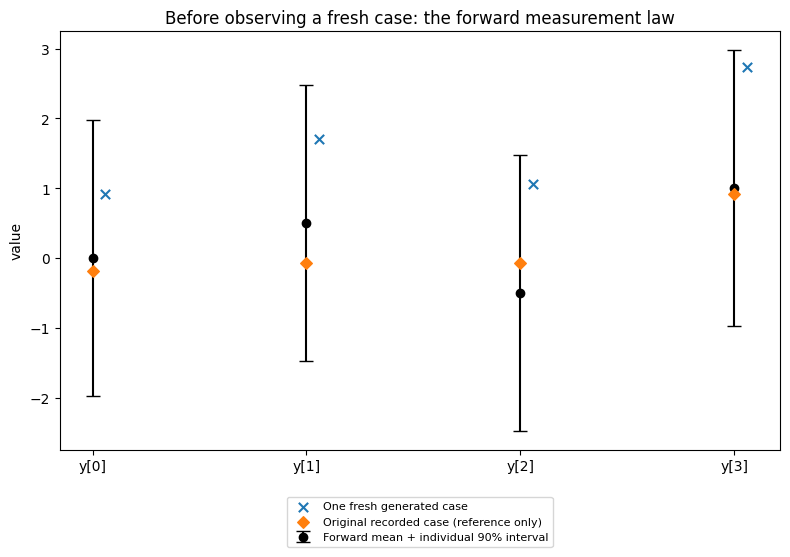

In [16]:
_ = plot_forward_measurements(mu_y, Sigma_yy, y_new, y)

### 6.2 What did generation establish? — prose

We used one fresh `z_new`, independent `epsilon_new`, and `y_new = W @ z_new + b + epsilon_new`. Explain why this generates a new possible case rather than imputing the old case, and why agreement of a displayed measurement with a marginal interval would not verify the forward mean/covariance or validate the model.

The new state is drawn from the unconditional state law and is not conditioned on the old measurement. Its new measurement follows the LGS equation with fresh independent noise, so the pair is a new possible case. Old-case imputation instead conditions on `x2_obs`. One draw illustrates model generation; it does not estimate or empirically verify a mean/covariance, and an individual interval is not a model-validation test.

**[GIVEN] Section summary.** We generated one fresh state/measurement pair by the LGS vector equation. Generation uses the known law for a new case; it does not compute or approximate the old-case conditional.

## 7. Supplied technical verification and consolidation

**[GIVEN] Author verification, not student implementation.** The following assertions check dimensions, symmetry, positive definiteness and the fixed-case conditional numerical results. For a symmetric covariance, `np.linalg.eigvalsh` returns eigenvalues; positivity checks that the Gaussian law is nonsingular. `np.testing.assert_allclose` raises an error if a claimed equality fails within tolerance. The covariance reduction is checked positive semidefinite. These software checks support the worked solution, rather than add a new student method.

In [17]:
assert mu.shape == (7,) and Sigma.shape == (7,7)
assert conditional_mean.shape == (3,) and conditional_cov.shape == (3,3)
assert W.shape == (4,3) and b.shape == (4,) and Omega.shape == (4,4)
for covariance in (Sigma, conditional_cov, Omega):
    np.testing.assert_allclose(covariance, covariance.T, atol=1e-14, rtol=0)
    assert np.all(np.linalg.eigvalsh(covariance) > 0)
assert np.all(np.linalg.eigvalsh(Sigma11 - conditional_cov) > -1e-12)
np.testing.assert_allclose(conditional_mean, [-0.568,0.432,0.932], atol=5e-4, rtol=0)
np.testing.assert_allclose(conditional_sd, np.full(n1,0.683), atol=5e-4, rtol=0)
np.testing.assert_allclose(risk_mean, 1.399058823529412, atol=1e-12, rtol=0)
np.testing.assert_allclose(Sigma_zy, Sigma12, atol=1e-14, rtol=0)
np.testing.assert_allclose(mu_y, mu2, atol=1e-14, rtol=0)
np.testing.assert_allclose(Sigma_yy, Sigma22, atol=1e-14, rtol=0)
assert z_new.shape == (3,) and epsilon_new.shape == (4,) and y_new.shape == (4,)

# Algebraic population check of the independent-state/noise generator.
# A single random case cannot check population moments empirically.
base_cov = np.block([[Sigma_z, np.zeros((n1,n2))],
                     [np.zeros((n2,n1)), Omega]])
affine_map = np.block([[np.eye(n1), np.zeros((n1,n2))],
                       [W, np.eye(n2)]])
np.testing.assert_allclose(affine_map @ base_cov @ affine_map.T, Sigma, atol=1e-12, rtol=0)
np.testing.assert_allclose(np.concatenate([mu_z, mu_y]), mu, atol=1e-12, rtol=0)
print("Supplied author checks passed.")

Supplied author checks passed.


**[GIVEN] What this notebook established.** One known joint Gaussian answered the hidden-block conditional query exactly. Its covariance described uncertainty; squared loss selected its mean and minimum conditional model risk. The same joint was translated into an LGS, whose marginal described measurements before a fresh observation. One independent state/noise pair illustrated new-case generation.

These conclusions are exact **within the supplied Gaussian model**, up to floating-point calculation. Conditional uncertainty persists even with exact arithmetic. Model mismatch and ignored parameter uncertainty can still make an exact model answer unsuitable for a real reconstruction task; this controlled single-case exercise does not assess those errors.

**Source route.** These numerical parameters and case are course-constructed. For the method, the lecture's checked editions point to Murphy, *Probabilistic Machine Learning: An Introduction* (April 18, 2025), §3.2.5 “Example: Imputing missing values” and §5.1.5.1 “L2 loss”; and *Probabilistic Machine Learning: Advanced Topics* (December 10, 2025), §2.3.1.3 “Marginals and conditionals of an MVN,” §2.3.2.1 “Joint distribution” and §2.3.2.2 “Posterior distribution (Bayes’ rule for Gaussians).” Read for block conditioning, loss selecting the mean, and reuse of one joint for inverse/forward queries. The vector risk identity is the lecture's elaboration of squared-loss optimality.